In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

## Генерация данных

In [8]:
X_cls, y_cls = make_classification(
    n_samples=100, n_informative=2, n_features=2, n_redundant=0,
    n_clusters_per_class=1, random_state=13, class_sep=1.5
)

X_cls = X_cls.astype(np.float32)
y_cls = y_cls.astype(np.float32)

X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=13
)

## Визуализация данных

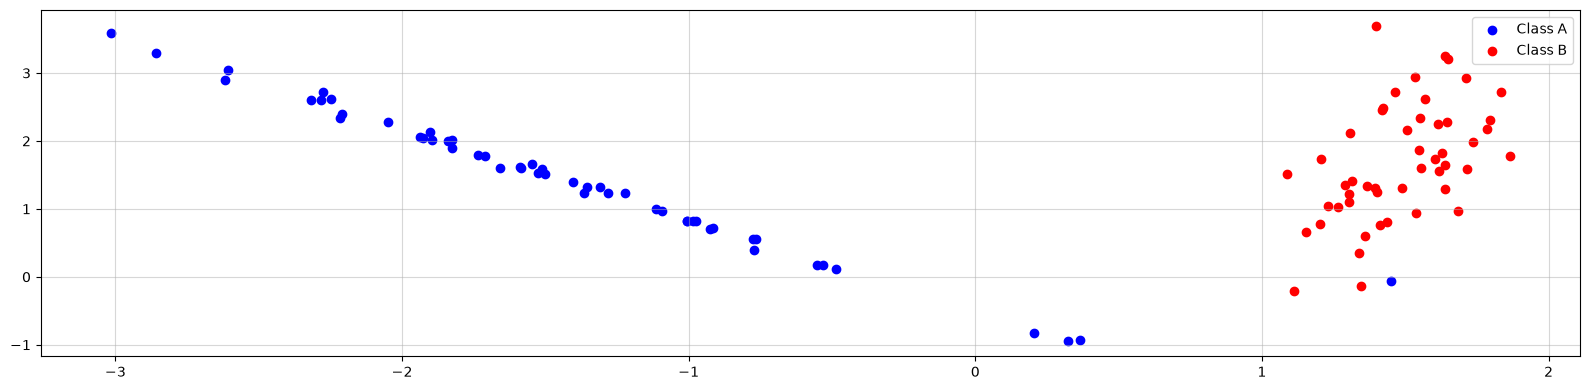

In [9]:
plt.figure(figsize=(16, 4))
plt.scatter(X_cls[y_cls == 0, 0], X_cls[y_cls == 0, 1], c='blue', label='Class A')
plt.scatter(X_cls[y_cls == 1, 0], X_cls[y_cls == 1, 1], c='red', label='Class B')
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Параметры модели обучения

In [3]:
X_train = torch.from_numpy(X_cls_train)
y_train = torch.from_numpy(y_cls_train).unsqueeze(-1)

model = nn.Sequential(
    nn.Linear(2, 1),
    nn.Sigmoid()
)
criterion = nn.BCELoss()
optimizator = optim.SGD(model.parameters(), lr=0.1)

n_epochs = 1000
losses = []

## Обучение модели

In [4]:
for epoch in range(n_epochs):

    optimizator.zero_grad()
    y_predicted = model(X_train)
    loss = criterion(y_predicted, y_train)
    losses.append(loss.item())
    
    loss.backward()
    optimizator.step()

    if(epoch + 1) % 40 == 0:
        print(f"Эпоха {epoch + 1}: loss={loss.item():.4f}")

Эпоха 40: loss=0.1617
Эпоха 80: loss=0.0956
Эпоха 120: loss=0.0717
Эпоха 160: loss=0.0588
Эпоха 200: loss=0.0506
Эпоха 240: loss=0.0448
Эпоха 280: loss=0.0404
Эпоха 320: loss=0.0369
Эпоха 360: loss=0.0340
Эпоха 400: loss=0.0316
Эпоха 440: loss=0.0295
Эпоха 480: loss=0.0278
Эпоха 520: loss=0.0262
Эпоха 560: loss=0.0248
Эпоха 600: loss=0.0236
Эпоха 640: loss=0.0225
Эпоха 680: loss=0.0215
Эпоха 720: loss=0.0206
Эпоха 760: loss=0.0197
Эпоха 800: loss=0.0190
Эпоха 840: loss=0.0183
Эпоха 880: loss=0.0176
Эпоха 920: loss=0.0170
Эпоха 960: loss=0.0165
Эпоха 1000: loss=0.0159


## График потерь

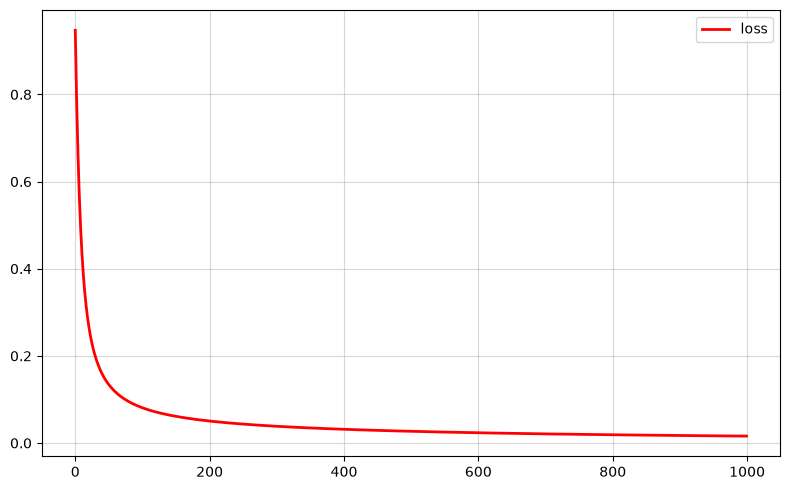

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(losses, color='red', label='loss', linewidth=2)
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()